Verifying base case replication...
  FY26E: Rev=15374, EBIT=1660, Capex=1999, ΔNWC=777, UFCF=1379
  FY27E: Rev=16732, EBIT=2150, Capex=2343, ΔNWC=334, UFCF=1112
  FY28E: Rev=18094, EBIT=2398, Capex=2714, ΔNWC=335, UFCF=1066
  FY29E: Rev=19411, EBIT=2431, Capex=2912, ΔNWC=324, UFCF=1027
  FY30E: Rev=20691, EBIT=2748, Capex=3104, ΔNWC=315, UFCF=1254

  Base case price: €20.94 (model: €25.56)

Running 10,000 simulations...

  MONTE CARLO RESULTS — 10,000 Simulations
  Mean:                      €   21.03
  Median:                    €   20.34
  Std Dev:                   €    9.31
  10th Percentile (Bear):    €    9.46
  25th Percentile:           €   14.40
  75th Percentile:           €   26.74
  90th Percentile (Bull):    €   33.04
  Current Market Price:       €23.00
  % above market:             38.7%
  % below market:             61.3%
  P(>50% upside):             8.0%


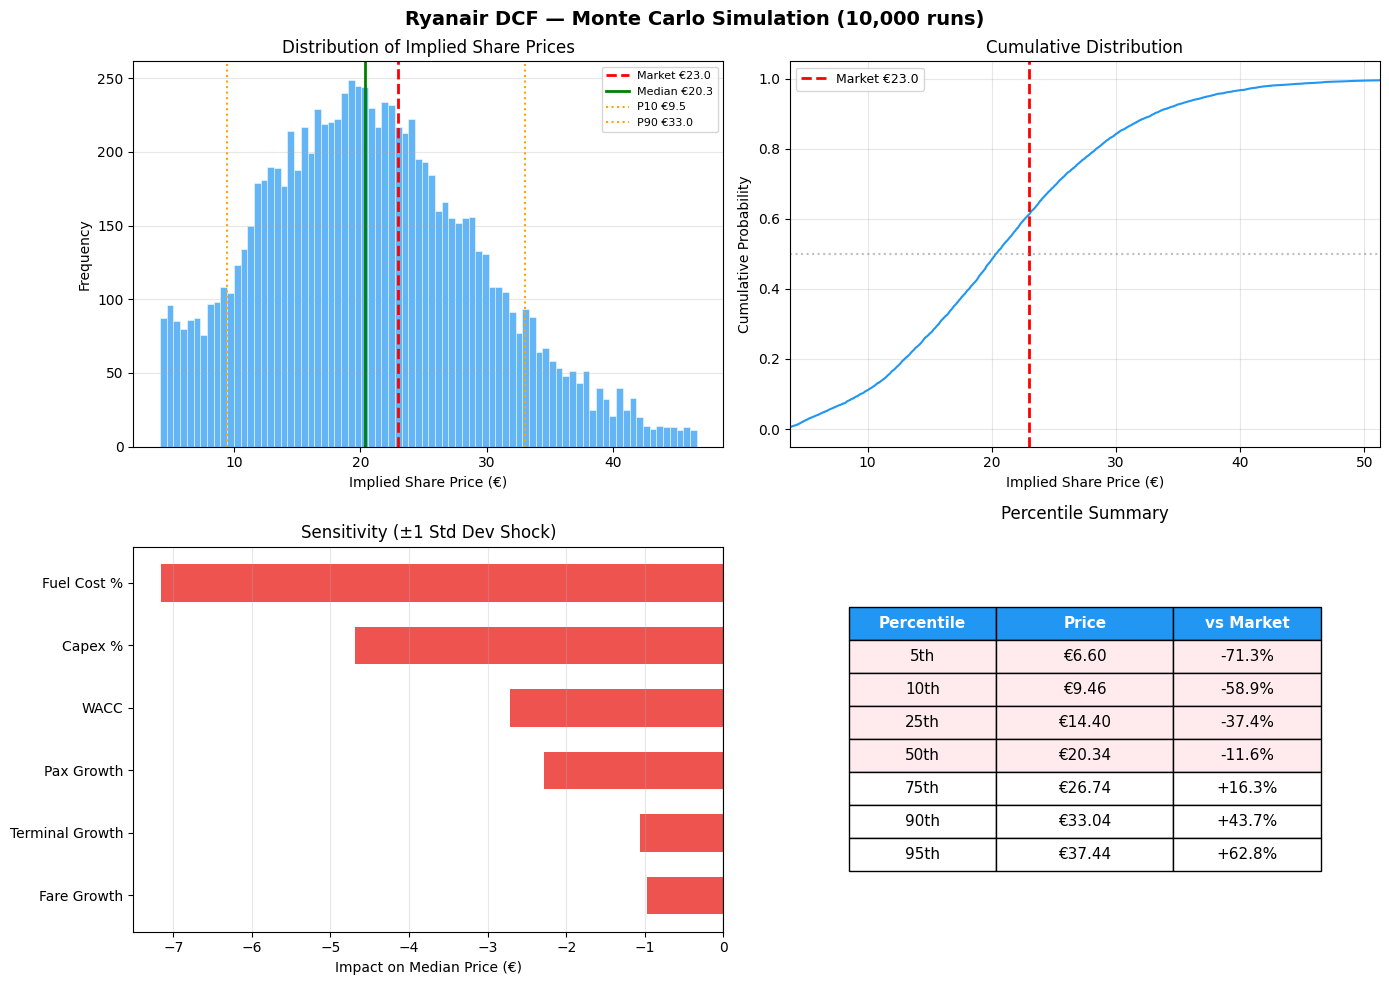


Chart saved as 'ryanair_monte_carlo.png'
Data saved as 'ryanair_monte_carlo_results.csv'


In [1]:
"""
Ryanair DCF — Monte Carlo Simulation (Final)

Requirements: numpy, pandas, matplotlib
Usage: python ryanair_monte_carlo.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)


# BASE CASE


# FY25A actuals
FY25_PAX = 200.2
FY25_FARE = 46.10
FY25_ANCIL_PP = 23.57
FY25_REVENUE = 13948.5
FY25_PPE = 11072.2
CASH = 3986.5
TOTAL_DEBT = 2534.0
LEASE_LIAB = 111.4
DILUTED_SHARES = 1095
DA_PCT = 0.10

# FY25A NWC position (from WC schedule)
FY25_NWC = -3005.9  # Negative NWC = Ryanair collects before it pays

# Working capital assumptions (DSO, DPO, DIO, OCA%, OCL%)
DSO = 10; DPO = 60; DIO = 4
OCA_PCT = 0.08; OCL_PCT = 0.20

N_SIMS = 10000
N_YEARS = 5

# Forecast assumptions from your model
PAX_GROWTH_BASE = np.array([0.07, 0.06, 0.055, 0.05, 0.045])
FARE_GROWTH_BASE = np.array([0.02, 0.025, 0.025, 0.02, 0.02])
ANCIL_GROWTH_BASE = np.array([0.05, 0.03, 0.025, 0.025, 0.02])

FUEL_BASE = np.array([0.40, 0.37, 0.36, 0.36, 0.35])
STAFF_BASE = np.array([0.12, 0.12, 0.12, 0.12, 0.12])
AIRPORT_BASE = np.array([0.15, 0.16, 0.165, 0.17, 0.17])
ROUTE_BASE = np.array([0.07, 0.07, 0.07, 0.07, 0.07])
MAINT_BASE = np.array([0.03, 0.03, 0.03, 0.03, 0.03])
MKTG_BASE = np.array([0.01, 0.01, 0.01, 0.01, 0.01])
OTHER_BASE = np.array([0.04, 0.04, 0.04, 0.04, 0.04])

CAPEX_BASE = np.array([0.13, 0.14, 0.15, 0.15, 0.15])
TAX_BASE = np.array([0.10, 0.105, 0.11, 0.11, 0.11])

WACC_BASE = 0.0738
TG_BASE = 0.02

# Standard deviations for randomisation
PAX_STD = 0.015
FARE_STD = 0.01
ANCIL_STD = 0.01
FUEL_STD = 0.025
COST_STD = 0.008
CAPEX_STD = 0.015
TAX_STD = 0.01
WACC_STD = 0.008
TG_STD = 0.004



# SIMULATION


def trunc(base, std, n, lo, hi):
    return np.clip(np.random.normal(base, std, n), lo, hi)

def compute_nwc(revenue):
    """Compute NWC from DSO/DPO/DIO, same as your WC schedule."""
    recv = revenue * DSO / 365
    inv = revenue * DIO / 365
    oca = revenue * OCA_PCT
    total_ca = recv + inv + oca
    payables = revenue * DPO / 365
    ocl = revenue * OCL_PCT
    total_cl = payables + ocl
    return total_ca - total_cl  # Negative for Ryanair

def run():
    prices = np.zeros(N_SIMS)
    evs = np.zeros(N_SIMS)

    for i in range(N_SIMS):
        # Draw random inputs
        pg = trunc(PAX_GROWTH_BASE, PAX_STD, 5, -0.02, 0.12)
        fg = trunc(FARE_GROWTH_BASE, FARE_STD, 5, -0.02, 0.05)
        ag = trunc(ANCIL_GROWTH_BASE, ANCIL_STD, 5, -0.01, 0.05)

        fuel = trunc(FUEL_BASE, FUEL_STD, 5, 0.30, 0.48)
        staff = trunc(STAFF_BASE, COST_STD, 5, 0.09, 0.15)
        airport = trunc(AIRPORT_BASE, COST_STD, 5, 0.12, 0.22)
        route = trunc(ROUTE_BASE, COST_STD, 5, 0.04, 0.10)
        maint = trunc(MAINT_BASE, COST_STD, 5, 0.015, 0.05)
        mktg = trunc(MKTG_BASE, COST_STD, 5, 0.005, 0.025)
        other = trunc(OTHER_BASE, COST_STD, 5, 0.02, 0.06)

        cap = trunc(CAPEX_BASE, CAPEX_STD, 5, 0.07, 0.22)
        tax = trunc(TAX_BASE, TAX_STD, 5, 0.05, 0.18)

        wacc = trunc(WACC_BASE, WACC_STD, 1, 0.05, 0.10)[0]
        tg = trunc(TG_BASE, TG_STD, 1, 0.005, 0.035)[0]
        if wacc - tg < 0.02:
            tg = wacc - 0.02

        # 5-year forecast
        ppax, pfare, pancil = FY25_PAX, FY25_FARE, FY25_ANCIL_PP
        prev_ppe = FY25_PPE
        prev_nwc = FY25_NWC
        ufcf = np.zeros(5)

        for y in range(5):
            pax = ppax * (1 + pg[y])
            fare = pfare * (1 + fg[y])
            ancil = pancil * (1 + ag[y])
            rev = pax * fare + pax * ancil

            # OpEx (excl D&A)
            cost_pct = fuel[y]+staff[y]+airport[y]+route[y]+maint[y]+mktg[y]+other[y]
            opex = rev * cost_pct

            # D&A
            da = prev_ppe * DA_PCT

            # EBIT and NOPAT
            ebit = rev - opex - da
            nopat = ebit * (1 - tax[y])

            # Capex
            capex = rev * cap[y]

            # NWC (DSO/DPO/DIO based, same as your model)
            nwc = compute_nwc(rev)
            delta_nwc = -(nwc - prev_nwc)  # Decrease in NWC = cash inflow

            # UFCF
            ufcf[y] = nopat + da - capex + delta_nwc

            # Roll forward
            ppax, pfare, pancil = pax, fare, ancil
            prev_ppe = prev_ppe + capex - da
            prev_nwc = nwc

        # Discount (mid-year convention)
        periods = np.array([0.5, 1.5, 2.5, 3.5, 4.5])
        df = 1 / (1 + wacc) ** periods
        pv_fcfs = np.sum(ufcf * df)

        # Terminal value (Gordon Growth)
        tv = max(0, ufcf[4] * (1 + tg) / (wacc - tg))
        pv_tv = tv / (1 + wacc) ** 5

        ev = pv_fcfs + pv_tv
        evs[i] = ev
        equity = ev + CASH - TOTAL_DEBT - LEASE_LIAB
        prices[i] = equity / DILUTED_SHARES

    return prices, evs



# VERIFY BASE CASE FIRST


print("Verifying base case replication...")
ppax, pfare, pancil = FY25_PAX, FY25_FARE, FY25_ANCIL_PP
prev_ppe, prev_nwc = FY25_PPE, FY25_NWC
for y in range(5):
    pax = ppax*(1+PAX_GROWTH_BASE[y])
    fare = pfare*(1+FARE_GROWTH_BASE[y])
    ancil = pancil*(1+ANCIL_GROWTH_BASE[y])
    rev = pax*fare + pax*ancil
    cost = FUEL_BASE[y]+STAFF_BASE[y]+AIRPORT_BASE[y]+ROUTE_BASE[y]+MAINT_BASE[y]+MKTG_BASE[y]+OTHER_BASE[y]
    da = prev_ppe*DA_PCT
    ebit = rev*(1-cost)-da
    nopat = ebit*(1-TAX_BASE[y])
    capex = rev*CAPEX_BASE[y]
    nwc = compute_nwc(rev)
    dnwc = -(nwc - prev_nwc)
    ufcf = nopat+da-capex+dnwc
    print(f"  FY{26+y}E: Rev={rev:.0f}, EBIT={ebit:.0f}, Capex={capex:.0f}, ΔNWC={dnwc:.0f}, UFCF={ufcf:.0f}")
    ppax,pfare,pancil = pax,fare,ancil
    prev_ppe = prev_ppe+capex-da; prev_nwc = nwc

# Full valuation
ppax, pfare, pancil = FY25_PAX, FY25_FARE, FY25_ANCIL_PP
prev_ppe, prev_nwc = FY25_PPE, FY25_NWC
ufcf_base = []
for y in range(5):
    pax=ppax*(1+PAX_GROWTH_BASE[y]); fare=pfare*(1+FARE_GROWTH_BASE[y]); ancil=pancil*(1+ANCIL_GROWTH_BASE[y])
    rev=pax*fare+pax*ancil
    cost=FUEL_BASE[y]+STAFF_BASE[y]+AIRPORT_BASE[y]+ROUTE_BASE[y]+MAINT_BASE[y]+MKTG_BASE[y]+OTHER_BASE[y]
    da=prev_ppe*DA_PCT; ebit=rev*(1-cost)-da; nopat=ebit*(1-TAX_BASE[y])
    capex=rev*CAPEX_BASE[y]; nwc=compute_nwc(rev); dnwc=-(nwc-prev_nwc)
    ufcf_base.append(nopat+da-capex+dnwc)
    ppax,pfare,pancil=pax,fare,ancil; prev_ppe=prev_ppe+capex-da; prev_nwc=nwc

periods=np.array([0.5,1.5,2.5,3.5,4.5])
df=1/(1+WACC_BASE)**periods
pv=sum(u*d for u,d in zip(ufcf_base,df))
tv=ufcf_base[4]*(1+TG_BASE)/(WACC_BASE-TG_BASE)
pvtv=tv/(1+WACC_BASE)**5
ev=pv+pvtv; eq=ev+CASH-TOTAL_DEBT-LEASE_LIAB
print(f"\n  Base case price: €{eq/DILUTED_SHARES:.2f} (model: €25.56)")



# RUN MONTE CARLO

print(f"\nRunning {N_SIMS:,} simulations...")
prices, evs = run()

current = 23.0
p1, p99 = np.percentile(prices, [1, 99])
clean = prices[(prices >= p1) & (prices <= p99)]

print(f"\n{'='*55}")
print(f"  MONTE CARLO RESULTS — {N_SIMS:,} Simulations")
print(f"{'='*55}")
print(f"  Mean:                      €{np.mean(prices):>8.2f}")
print(f"  Median:                    €{np.median(prices):>8.2f}")
print(f"  Std Dev:                   €{np.std(prices):>8.2f}")
print(f"  10th Percentile (Bear):    €{np.percentile(prices, 10):>8.2f}")
print(f"  25th Percentile:           €{np.percentile(prices, 25):>8.2f}")
print(f"  75th Percentile:           €{np.percentile(prices, 75):>8.2f}")
print(f"  90th Percentile (Bull):    €{np.percentile(prices, 90):>8.2f}")
print(f"{'='*55}")
print(f"  Current Market Price:       €{current:.2f}")
print(f"  % above market:             {np.mean(prices > current)*100:.1f}%")
print(f"  % below market:             {np.mean(prices < current)*100:.1f}%")
print(f"  P(>50% upside):             {np.mean(prices > current*1.5)*100:.1f}%")



# CHARTS


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Ryanair DCF — Monte Carlo Simulation (10,000 runs)', fontsize=14, fontweight='bold')

# 1. Histogram
ax = axes[0, 0]
ax.hist(clean, bins=80, color='#2196F3', alpha=0.7, edgecolor='white', linewidth=0.5)
ax.axvline(current, color='red', ls='--', lw=2, label=f'Market €{current}')
ax.axvline(np.median(prices), color='green', lw=2, label=f'Median €{np.median(prices):.1f}')
ax.axvline(np.percentile(prices, 10), color='orange', ls=':', lw=1.5, label=f'P10 €{np.percentile(prices,10):.1f}')
ax.axvline(np.percentile(prices, 90), color='orange', ls=':', lw=1.5, label=f'P90 €{np.percentile(prices,90):.1f}')
ax.set_xlabel('Implied Share Price (€)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Implied Share Prices')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# 2. CDF
ax = axes[0, 1]
s = np.sort(prices)
cdf = np.arange(1, len(s)+1) / len(s)
ax.plot(s, cdf, color='#2196F3', lw=1.5)
ax.axvline(current, color='red', ls='--', lw=2, label=f'Market €{current}')
ax.axhline(0.5, color='grey', ls=':', alpha=0.5)
ax.set_xlabel('Implied Share Price (€)')
ax.set_ylabel('Cumulative Probability')
ax.set_title('Cumulative Distribution')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(max(0, np.percentile(prices, 1)*0.9), np.percentile(prices, 99)*1.1)

# 3. Tornado
ax = axes[1, 0]
base_med = np.median(prices)

def shocked_run(var, direction):
    pp = np.zeros(2000)
    for j in range(2000):
        pg=trunc(PAX_GROWTH_BASE,PAX_STD,5,-0.02,0.12)
        fg=trunc(FARE_GROWTH_BASE,FARE_STD,5,-0.02,0.05)
        ag=trunc(ANCIL_GROWTH_BASE,ANCIL_STD,5,-0.01,0.05)
        fl=trunc(FUEL_BASE,FUEL_STD,5,0.30,0.48)
        st=trunc(STAFF_BASE,COST_STD,5,0.09,0.15)
        ap=trunc(AIRPORT_BASE,COST_STD,5,0.12,0.22)
        rt=trunc(ROUTE_BASE,COST_STD,5,0.04,0.10)
        mt=trunc(MAINT_BASE,COST_STD,5,0.015,0.05)
        mk=trunc(MKTG_BASE,COST_STD,5,0.005,0.025)
        ot=trunc(OTHER_BASE,COST_STD,5,0.02,0.06)
        cp=trunc(CAPEX_BASE,CAPEX_STD,5,0.07,0.22)
        tx=trunc(TAX_BASE,TAX_STD,5,0.05,0.18)
        w=trunc(WACC_BASE,WACC_STD,1,0.05,0.10)[0]
        t=trunc(TG_BASE,TG_STD,1,0.005,0.035)[0]

        if var=='fuel': fl=FUEL_BASE+direction*FUEL_STD
        elif var=='wacc': w=WACC_BASE+direction*WACC_STD
        elif var=='tg': t=TG_BASE+direction*TG_STD
        elif var=='pax': pg=PAX_GROWTH_BASE+direction*PAX_STD
        elif var=='fare': fg=FARE_GROWTH_BASE+direction*FARE_STD
        elif var=='capex': cp=CAPEX_BASE+direction*CAPEX_STD

        if w-t<0.02: t=w-0.02

        ppx,pfr,pan=FY25_PAX,FY25_FARE,FY25_ANCIL_PP
        ppe,nwc_=FY25_PPE,FY25_NWC; ufcf=np.zeros(5)
        for y in range(5):
            px=ppx*(1+pg[y]);fr=pfr*(1+fg[y]);an=pan*(1+ag[y])
            rv=px*fr+px*an
            cpct=fl[y]+st[y]+ap[y]+rt[y]+mt[y]+mk[y]+ot[y]
            da=ppe*DA_PCT;eb=rv*(1-cpct)-da;np_=eb*(1-tx[y])
            cx=rv*cp[y];nw=compute_nwc(rv);dn=-(nw-nwc_)
            ufcf[y]=np_+da-cx+dn
            ppx,pfr,pan=px,fr,an;ppe=ppe+cx-da;nwc_=nw

        per=np.array([0.5,1.5,2.5,3.5,4.5])
        d=1/(1+w)**per;pv=np.sum(ufcf*d)
        tv_=max(0,ufcf[4]*(1+t)/(w-t));pvt=tv_/(1+w)**5
        eq=pv+pvt+CASH-TOTAL_DEBT-LEASE_LIAB
        pp[j]=eq/DILUTED_SHARES
    return np.median(pp)

tests = [('Fuel Cost %','fuel',1),('WACC','wacc',1),('Terminal Growth','tg',-1),
         ('Capex %','capex',1),('Pax Growth','pax',-1),('Fare Growth','fare',-1)]
labels,impacts=[],[]
for lbl,var,d in tests:
    m=shocked_run(var,d); labels.append(lbl); impacts.append(m-base_med)

idx=np.argsort(np.abs(impacts))
labels=[labels[i] for i in idx]; impacts=[impacts[i] for i in idx]
colors=['#ef5350' if x<0 else '#66bb6a' for x in impacts]
ax.barh(labels,impacts,color=colors,height=0.6)
ax.axvline(0,color='black',lw=0.8)
ax.set_xlabel('Impact on Median Price (€)')
ax.set_title('Sensitivity (±1 Std Dev Shock)')
ax.grid(axis='x',alpha=0.3)

# 4. Percentile table
ax = axes[1, 1]; ax.axis('off')
pctiles = [5, 10, 25, 50, 75, 90, 95]
vals = [np.percentile(prices, p) for p in pctiles]
tbl = [[f'{p}th', f'€{v:.2f}', f'{(v/current-1)*100:+.1f}%'] for p,v in zip(pctiles,vals)]
table = ax.table(cellText=tbl, colLabels=['Percentile','Price','vs Market'],
                 cellLoc='center', loc='center', colWidths=[0.25,0.3,0.25])
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1,1.8)
for j in range(3):
    table[0,j].set_facecolor('#2196F3')
    table[0,j].set_text_props(color='white',fontweight='bold')
for i,v in enumerate(vals):
    if v<current:
        for j in range(3): table[i+1,j].set_facecolor('#ffebee')
ax.set_title('Percentile Summary', fontsize=12, pad=20)

plt.tight_layout()
plt.savefig('ryanair_monte_carlo.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nChart saved as 'ryanair_monte_carlo.png'")

df = pd.DataFrame({'simulation':range(1,N_SIMS+1),'implied_share_price':prices,'enterprise_value':evs})
df.to_csv('ryanair_monte_carlo_results.csv', index=False)
print("Data saved as 'ryanair_monte_carlo_results.csv'")